# Lifetime from a TCSPC decay with a blind IRF — the λ–m approach

This notebook takes one decay histogram, extracts the instrument response function (IRF) **from the decay itself**, and fits the fluorescence lifetime τ by reconvolution.

**The idea** (BIRFI: Gómez-Sánchez *et al.*, *Biophys. Rep.* **4**, 100155, 2024). Once the IRF has finished acting — from a cutting point *m* onwards — the measured decay is the underlying exponential, merely scaled. That tail, shifted to the origin, *is* the decay *x*, so the IRF follows from *y* = IRF ⊛ *x* by deconvolution.

**The λ–m approach.** The method leaves two choices open: the smoothing strength λ and the cut *m*. We try a grid of (λ, *m*) pairs, score each by how well its IRF explains the raw counts (Poisson deviance of a reconvolution fit), and keep the best. The τ from that best fit is the lifetime.

| Step | What it does |
|---|---|
| 1 | load the decay, crop it to start just before the rise, estimate the background |
| 2 | measure the rise time, which sets the scale of every λ |
| 3 | find a starting cut *m*₀ at the minimum of the derivative |
| 4 | λ–m scan: for every pair, smooth → deconvolve → fit τ |
| 5 | choose the best pair; report τ with statistical and systematic errors |

Requires NumPy, SciPy, Matplotlib and the `whittaker-eilers` package (`pip install whittaker-eilers`).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import nnls, minimize_scalar, brentq
from whittaker_eilers import WhittakerSmoother      # pip install whittaker-eilers

DATA_FILE = "LifeTimeHistogramCh1.csv"    # two columns: time (ns), counts; '#' lines are comments

## Step 1 · Load the decay, estimate the background, crop the window

The window must start **before** the rise: the IRF is placed relative to the first bin, and its whole leading edge has to be inside. Starting only shortly before keeps the IRF short — fewer unknowns to solve for.

In [2]:
def load_decay(path):
    """
    Read a TCSPC histogram from a two-column CSV file.

    Why:    every later step works on the time axis and the counts as NumPy arrays.
    Input:  path - text file with two comma-separated columns, time (ns) and counts
            (photons per bin). Lines starting with '#' are a header and are skipped.
    Output: time_ns - start time of each bin (ns)
            counts  - photons recorded in each bin
    Used by: estimate_background and crop_before_rise.
    """
    data = np.loadtxt(path, delimiter=",", comments="#")
    time_ns = data[:, 0]
    counts = data[:, 1]
    return time_ns, counts


def estimate_background(counts, tail_fraction=0.10):
    """
    Flat background level: dark counts and stray light, present in every bin.

    Why:    the deconvolution must see only the fluorescence decay, so the background is
            subtracted first (steps 3-4). The far tail is used because the fluorescence
            has died away there; the median ignores the occasional outlier bin.
    Input:  counts        - photons per bin (the whole file)
            tail_fraction - fraction of the last bins used (default: last 10 %)
    Output: background (photons per bin)
    Used by: crop_before_rise (to find the rise), measure_rise_time, and to form the
             background-subtracted decay y used in steps 3 and 4.
    """
    n_tail_bins = max(10, int(tail_fraction * counts.size))
    return float(np.median(counts[-n_tail_bins:]))


def crop_before_rise(time_ns, counts, background, margin_ns=0.8, rise_threshold=0.02):
    """
    Keep only the part of the histogram from shortly before the pulse onwards.

    Why:    BIRFI positions the IRF relative to the first bin of the window and counts its
            length from there (IRF length = m + 1 bins). Starting just before the rise keeps
            the IRF short while keeping its whole leading edge inside the window.
    Input:  time_ns, counts - the full histogram
            background      - photons per bin (from estimate_background)
            margin_ns       - how far before the rise the window starts (ns); increase it
                              for very broad IRFs
            rise_threshold  - the rise is the first bin exceeding this fraction of the
                              peak height above background
    Output: time_ns, counts - the cropped window
            first_bin       - index of the window's first bin in the original file
    Used by: every later step works on the cropped arrays.
    """
    height_above_background = counts - background
    first_rising_bin = int(np.argmax(height_above_background >
                                     rise_threshold * height_above_background.max()))
    bin_width_ns = np.median(np.diff(time_ns))
    first_bin = max(0, first_rising_bin - int(round(margin_ns / bin_width_ns)))
    return time_ns[first_bin:], counts[first_bin:], first_bin


# --- run step 1 on the data ---
time_all_ns, counts_all = load_decay(DATA_FILE)
background = estimate_background(counts_all)
time_ns, counts, first_bin = crop_before_rise(time_all_ns, counts_all, background)
y = counts - background          # background-subtracted decay: the input of steps 3 and 4
bin_width_ns = time_ns[1] - time_ns[0]

print(f"file: {counts_all.size} bins of {bin_width_ns * 1000:.0f} ps, peak {counts_all.max():.0f} counts")
print(f"background (far-tail median): {background:.1f} counts/bin")
print(f"window: {time_ns[0]:.2f} – {time_ns[-1]:.2f} ns ({counts.size} bins, from bin {first_bin} of the file)")

file: 250 bins of 100 ps, peak 49667 counts
background (far-tail median): 27.0 counts/bin
window: 1.00 – 24.90 ns (240 bins, from bin 10 of the file)


## Step 2 · Rise time, and λ as a cutoff period

The order-2 Whittaker smoother is a low-pass filter with gain $H(\omega) = 1/(1 + 16\lambda\sin^4(\omega/2))$. Its gain falls to ½ at the period $T_c$ (in bins) when $\lambda = (2\sin(\pi/T_c))^{-4}$. So every λ below is chosen as a cutoff period, and the rise time — a proxy for the IRF width — sets that scale.

In [3]:
def measure_rise_time(counts, background):
    """
    10-90 % rise time of the decay's leading edge, in bins.

    Why:    the rising edge is shaped by the IRF, so its duration is a proxy for the IRF
            width. It sets the scale of both smoothing choices: the derivative smoothing in
            step 3 and the λ grid in step 4. Measured on the raw counts: the edge has many
            counts per bin, and smoothing it would only make it look slower.
    Input:  counts     - photons per bin (cropped window)
            background - photons per bin
    Output: rise_bins - rise time in bins (fractional, by linear interpolation)
    Used by: find_initial_cut and make_lambda_grid.
    """
    height = counts - background
    peak_bin = int(np.argmax(height))
    edge = height[: peak_bin + 1] / height[peak_bin]     # leading edge, normalised to 1 at the peak

    def crossing_bin(level):
        # last bin below 'level' before the peak, then linear interpolation into the next bin
        below = np.flatnonzero(edge < level)[-1]
        return below + (level - edge[below]) / (edge[below + 1] - edge[below])

    return crossing_bin(0.9) - crossing_bin(0.1)


def lambda_for_cutoff(cutoff_bins):
    """
    Whittaker penalty λ whose filter passes half the amplitude at the given period.

    Why:    λ is hard to choose directly (it is a length to the fourth power, in bins^4);
            a cutoff period is easy to reason about. This is the exact relation, without the
            small-angle approximation, valid for cutoff periods of at least 2 bins (Nyquist).
    Input:  cutoff_bins - period at which the gain is 1/2 (bins, >= 2)
    Output: λ (bins^4)
    Used by: find_initial_cut (λ for the derivative) and make_lambda_grid.
    """
    cutoff_bins = max(cutoff_bins, 2.0)
    return (2.0 * np.sin(np.pi / cutoff_bins)) ** -4


def cutoff_for_lambda(lam):
    """
    Inverse of lambda_for_cutoff: the half-gain period of a given λ, in bins.

    Why:    to report the chosen λ in meaningful terms.
    Input:  lam - λ (bins^4)
    Output: cutoff period (bins), or None when the gain stays above 1/2 up to Nyquist
            (λ < 1/16: such a λ only tilts the top of the spectrum, it has no cutoff).
    Used by: print_summary only.
    """
    if lam <= 0:
        return None
    half_gain_sine = 0.5 * lam ** -0.25
    return np.pi / np.arcsin(half_gain_sine) if half_gain_sine < 1 else None


# --- run step 2 on the data ---
rise_bins = measure_rise_time(counts, background)
print(f"rise time (10-90 %): {rise_bins:.2f} bins = {rise_bins * bin_width_ns:.3f} ns")
print(f"λ for a cutoff of 3 x rise  (derivative, step 3): {lambda_for_cutoff(3.0 * rise_bins):.3g}")
print(f"λ for a cutoff of 1.5 x rise (top of the grid, step 4): {lambda_for_cutoff(1.5 * rise_bins):.3g}")

rise time (10-90 %): 4.25 bins = 0.425 ns
λ for a cutoff of 3 x rise  (derivative, step 3): 17.7
λ for a cutoff of 1.5 x rise (top of the grid, step 4): 1.25


## Step 3 · Starting cut *m*₀

From the cut onwards the decay is the pure exponential, and the frontier shows up as the minimum of $dy/dt$ (SI Eq. S6). The derivative amplifies noise, so it is taken on a heavily smoothed trace. That is fine here: we only need the *location* of a broad minimum, and the scan in step 4 refines *m* anyway.

In [4]:
def whittaker_smooth(y, lam):
    """
    Whittaker smoother: the curve z that minimises  ||y - z||^2 + λ ||D2 z||^2.

    Why:    the deconvolution and the derivative both amplify high-frequency noise; this
            removes it first. The first term keeps z close to the data, the second penalises
            curvature (D2 = second differences), and λ is the price of curvature: periods
            shorter than about 2π·λ^(1/4) bins are removed.
            Setting the gradient to zero gives (I + λ D2ᵀD2) z = y. The whittaker-eilers
            package solves exactly this system (Eilers' method, sparse LDLᵀ solver); the
            check below confirms it on the data.
            λ is always set by us - from a cutoff period or by the λ-m scan. The package's
            own smooth_optimal is deliberately not used: it picks λ to reproduce y, not to
            recover the IRF, and with break_serial_correlation=True it applies a λ found on
            every 5th point to the full series without the 5^4 rescaling λ needs.
    Input:  y   - data to smooth (here: counts above background)
            lam - λ (bins^4); λ = 0 returns y unchanged (the package needs λ > 0)
    Output: smoothed copy of y (NumPy array)
    Used by: find_initial_cut (heavy smoothing) and lambda_m_scan (one smoothing per λ).
    """
    if lam == 0:
        return y.copy()
    smoother = WhittakerSmoother(lmbda=float(lam), order=2, data_length=y.size)
    return np.array(smoother.smooth(y.tolist()))


def find_initial_cut(y, rise_bins):
    """
    Starting cut m0: the minimum of the derivative after the peak.

    Why:    from the cut onwards the decay equals the scaled underlying exponential (SI Eq.
            S5); the derivative minimum approximates that frontier (SI Eq. S6). It is only a
            starting point: the λ-m scan tries cuts around it.
            The derivative is taken on a trace smoothed with a cutoff of 3 x the rise time:
            heavy enough to locate the minimum reliably, which is all that is needed here.
    Input:  y         - counts above background (cropped window)
            rise_bins - rise time (bins)
    Output: m0 - bin index of the cut within the window
    Used by: make_m_grid.
    """
    smoothed = whittaker_smooth(y, lambda_for_cutoff(3.0 * rise_bins))
    derivative = np.gradient(smoothed)                  # counts per bin, per bin
    peak_bin = int(np.argmax(smoothed))
    return peak_bin + int(np.argmin(derivative[peak_bin:]))


# --- check: the package solves (I + λ D2ᵀD2) z = y, compared with a direct sparse solve ---
from scipy import sparse
from scipy.sparse.linalg import spsolve
lam_check = lambda_for_cutoff(3.0 * rise_bins)
second_difference = sparse.diags([1.0, -2.0, 1.0], [0, 1, 2], shape=(y.size - 2, y.size))
direct_solution = spsolve((sparse.identity(y.size) + lam_check * second_difference.T @ second_difference).tocsc(), y)
difference = np.abs(whittaker_smooth(y, lam_check) - direct_solution).max() / np.abs(y).max()
print(f"whittaker-eilers vs direct solve (λ = {lam_check:.3g}): max difference {difference:.1e} of the peak")

# --- run step 3 on the data ---
m0 = find_initial_cut(y, rise_bins)
print(f"starting cut m0 = {m0} bins into the window  ->  t = {time_ns[m0]:.2f} ns")

whittaker-eilers vs direct solve (λ = 17.7): max difference 1.2e-14 of the peak
starting cut m0 = 21 bins into the window  ->  t = 3.10 ns


## Step 4 · The λ–m scan

### 4a–c · From one (λ, *m*) pair to an IRF

The tail $x = y[m:]$ is the underlying decay up to a scale, and the decay is a sum of copies of it, one launched by each IRF sample. Polynomial long division (`np.polydiv`, identical to MATLAB's `deconv` in the paper's SI) peels those copies off from left to right; each peel gives one IRF sample.

In [5]:
def make_lambda_grid(rise_bins, n_values=13, n_decades=3):
    """
    The λ values tried in the scan.

    Why:    the best λ depends on the noise level and the IRF shape, so it is found by
            trying. λ = 0 (no smoothing) is always included; the others are log-spaced over
            n_decades below the λ whose cutoff is 1.5 x the rise time, so the grid stays
            tied to the IRF width in bins whatever the binning.
    Input:  rise_bins - rise time (bins)
    Output: array of λ values (bins^4), starting with 0
    Used by: lambda_m_scan.
    """
    lam_top = lambda_for_cutoff(1.5 * rise_bins)
    return np.concatenate([[0.0], np.geomspace(lam_top / 10 ** n_decades, lam_top, n_values)])


def make_m_grid(m0, n_bins, n_before=3, n_after=6):
    """
    The cuts m tried in the scan: from m0 - 3 to m0 + 6 bins.

    Why:    the derivative minimum is only approximate. Too early a cut truncates the IRF;
            too late a cut lets the surplus IRF samples absorb noise. More room is given
            after m0 than before, because cutting late is the gentler error.
    Input:  m0     - starting cut (bin index)
            n_bins - number of bins in the window
    Output: array of cut indices
    Used by: lambda_m_scan.
    """
    first = max(m0 - n_before, 1)
    last = min(m0 + n_after, n_bins - 10)        # keep at least 10 bins of tail
    return np.arange(first, last + 1)


def deconvolve_irf(y_smoothed, m):
    """
    The BIRFI deconvolution: IRF from the decay and its own tail.

    Why:    for t >= t[m] the IRF has finished acting, so the tail y[m:] is the underlying
            decay x up to a scale. Then y = IRF ⊛ x, and knowing y and x, the IRF follows by
            polynomial long division. Each division step: what is left of y at bin n can
            only come from IRF sample n, so h[n] = remainder[n] / x[0]; that sample's copy
            of the tail is then subtracted. The bin m is shared: the last IRF sample and the
            first tail sample.
    Input:  y_smoothed - counts above background, smoothed with the current λ
            m          - cut (bin index within the window)
    Output: raw IRF, m + 1 values (bins 0..m of the window), not yet normalised;
            its length is len(y) - len(tail) + 1 = m + 1
    Used by: normalise_irf.
    """
    tail = y_smoothed[m:]                        # the underlying decay x, up to a scale
    irf_raw, _remainder = np.polydiv(y_smoothed, tail)
    return irf_raw


def normalise_irf(irf_raw):
    """
    Make the raw IRF a physical, unit-area response.

    Why:    negative samples are noise, not physics, so they are clipped to zero. The IRF's
            overall scale is undetermined by BIRFI (it is absorbed by the amplitude A of the
            fit), so it is normalised to unit area.
    Input:  irf_raw - output of deconvolve_irf
    Output: IRF with unit area, or None if nothing positive is left (pair is skipped)
    Used by: the reconvolution fit (step 4d) and the final result.
    """
    irf = np.clip(irf_raw, 0.0, None)
    total = irf.sum()
    return irf / total if total > 0 else None


# --- run 4a-c on the data ---
lambda_grid = make_lambda_grid(rise_bins)
m_grid = make_m_grid(m0, counts.size)
print(f"λ grid ({lambda_grid.size} values): 0, {lambda_grid[1]:.3g} … {lambda_grid[-1]:.3g}")
print(f"m grid ({m_grid.size} values): {m_grid[0]} … {m_grid[-1]} bins "
      f"({time_ns[m_grid[0]]:.1f} – {time_ns[m_grid[-1]]:.1f} ns)")
example_irf = normalise_irf(deconvolve_irf(whittaker_smooth(y, lambda_grid[5]), m0))
print(f"example IRF (λ = {lambda_grid[5]:.3g}, m = {m0}): {example_irf.size} samples, "
      f"peak at t = {time_ns[np.argmax(example_irf)]:.2f} ns")

λ grid (14 values): 0, 0.00125 … 1.25
m grid (10 values): 18 … 27 bins (2.8 – 3.7 ns)
example IRF (λ = 0.0125, m = 21): 22 samples, peak at t = 2.20 ns


### 4d · Reconvolution fit with Poisson maximum likelihood

Model: $\mu = A\,(\mathrm{IRF} \circledast e^{-t/\tau}) + b$. For a fixed τ the model is linear in $A$ and $b$, so they are solved exactly; only τ is searched (variable projection). The fit uses Poisson maximum likelihood rather than least squares, which biases τ low when bins hold few counts.

In [6]:
def decay_shape(time_ns, irf, tau_ns):
    """
    Model decay shape for a trial lifetime: IRF ⊛ exp(-t/τ), unit amplitude.

    Why:    this is what the decay should look like if τ were the lifetime. It uses the same
            discrete convolution and time origin as the deconvolution, so no time-shift
            parameter is needed: the IRF came from this very decay and is aligned with it.
    Input:  time_ns - window time axis (ns)
            irf     - unit-area IRF (bins 0..m)
            tau_ns  - trial lifetime (ns)
    Output: shape, one value per bin of the window
    Used by: fit_amplitude_and_background (via profile_deviance) and the final model.
    """
    exponential = np.exp(-(time_ns - time_ns[0]) / tau_ns)
    return np.convolve(irf, exponential)[: time_ns.size]


def fit_amplitude_and_background(shape, counts, max_iterations=30):
    """
    Poisson maximum-likelihood amplitude A and background b, for a fixed lifetime.

    Why:    model = A·shape + b is linear in A and b. For Poisson counts, maximum likelihood
            equals weighted least squares with weights 1/model; since the weights depend on
            the model, the solve is repeated until they agree (iteratively reweighted least
            squares). scipy.optimize.nnls keeps A, b >= 0: physical, and necessary - a
            negative background can make the model negative and wreck the likelihood.
    Input:  shape  - output of decay_shape
            counts - raw photons per bin (window), NOT background-subtracted
    Output: amplitude A (counts), background b (counts per bin), model (expected counts per bin)
    Used by: profile_deviance (at every trial τ) and analyse_decay (final model).
    """
    design = np.column_stack([shape, np.ones_like(shape)])     # column 0: A term; column 1: b term
    weights = 1.0 / np.sqrt(np.maximum(counts, 1.0))           # first guess: variance ≈ counts
    params = nnls(design * weights[:, None], counts * weights)[0]
    for _ in range(max_iterations):
        model = np.maximum(design @ params, 1e-12)
        weights = 1.0 / np.sqrt(model)                         # Poisson: variance = expected counts
        new_params = nnls(design * weights[:, None], counts * weights)[0]
        converged = np.allclose(new_params, params, rtol=1e-10, atol=1e-12)
        params = new_params
        if converged:
            break
    amplitude, background_fit = params
    return amplitude, background_fit, design @ params


def poisson_deviance(counts, model):
    """
    Poisson deviance  D = 2 Σ [model - counts + counts·ln(counts/model)].

    Why:    it is -2 x the log-likelihood of the counts, relative to a model that matches
            every bin exactly. Minimising D is maximum likelihood. For a fit at the noise
            level D/dof ≈ 1, and D rising by 1 from its minimum marks one standard deviation
            of a single parameter. Bins with zero counts contribute only their model value.
    Input:  counts - raw photons per bin; model - expected photons per bin
    Output: D (dimensionless)
    Used by: profile_deviance, the λ-m scan score, and the final fit quality.
    """
    model = np.maximum(model, 1e-12)
    log_term = np.zeros_like(model)
    has_counts = counts > 0
    log_term[has_counts] = counts[has_counts] * np.log(counts[has_counts] / model[has_counts])
    return 2.0 * np.sum(model - counts + log_term)


def profile_deviance(tau_ns, time_ns, counts, irf):
    """
    Deviance at a trial τ, with A and b at their best values for that τ.

    Why:    this "profile" turns the three-parameter fit into a function of τ alone, which
            fit_lifetime minimises and lifetime_statistical_error scans.
    Input:  tau_ns (ns), time_ns, counts (raw), irf (unit area)
    Output: D (dimensionless)
    """
    shape = decay_shape(time_ns, irf, tau_ns)
    _, _, model = fit_amplitude_and_background(shape, counts)
    return poisson_deviance(counts, model)


def fit_lifetime(time_ns, counts, irf, n_coarse=40):
    """
    Best lifetime: the τ that minimises the profile deviance.

    Why:    two stages. A coarse log grid over every plausible lifetime (one bin up to the
            window length) finds the right valley; scipy's bounded minimize_scalar then
            refines τ between the two grid neighbours of the lowest point.
    Input:  time_ns, counts (raw), irf (unit area); n_coarse - points of the coarse grid
    Output: tau_ns (ns) and the deviance at the minimum
    Used by: lambda_m_scan (every pair) and therefore the final result.
    """
    coarse_taus = np.geomspace(time_ns[1] - time_ns[0], time_ns[-1] - time_ns[0], n_coarse)
    coarse_deviances = [profile_deviance(tau, time_ns, counts, irf) for tau in coarse_taus]
    k = int(np.argmin(coarse_deviances))
    bracket = (coarse_taus[max(k - 1, 0)], coarse_taus[min(k + 1, n_coarse - 1)])
    result = minimize_scalar(profile_deviance, bounds=bracket, method="bounded",
                             args=(time_ns, counts, irf), options={"xatol": 1e-6})
    return result.x, result.fun


# --- run 4d on the data, for the example pair ---
tau_example, deviance_example = fit_lifetime(time_ns, counts, example_irf)
print(f"example pair: tau = {tau_example:.4f} ns, deviance/dof = {deviance_example / (counts.size - 3):.3f}")

example pair: tau = 1.8678 ns, deviance/dof = 1.132


### 4e · Score every pair

Each λ is used to smooth once; every cut *m* is then tried on that smoothed trace. The score is the deviance per degree of freedom of the reconvolution fit, and τ is recorded alongside it.

In [7]:
def lambda_m_scan(time_ns, counts, y, lambda_grid, m_grid):
    """
    Fit every (λ, m) pair and record how well its IRF explains the raw counts.

    Why:    this is the λ-m approach: neither λ nor m is fixed by the method, so each pair
            is judged by the same Poisson deviance that is used to fit τ. Too little
            smoothing gives a ragged IRF, too much a broadened one; too early a cut truncates
            the IRF, too late adds noisy samples - all of these show up as a worse fit.
    Input:  time_ns, counts - window (raw counts)
            y               - counts above background (the deconvolution input)
            lambda_grid, m_grid - values to try
    Output: deviance_per_dof[i_lambda, i_m] (inf where a pair failed)
            tau_map[i_lambda, i_m]          (ns; nan where a pair failed)
    Used by: select_best_pair; the deviance map is also plotted.
    """
    degrees_of_freedom = counts.size - 3           # bins minus the fitted τ, A, b
    deviance_per_dof = np.full((lambda_grid.size, m_grid.size), np.inf)
    tau_map = np.full((lambda_grid.size, m_grid.size), np.nan)
    for i, lam in enumerate(lambda_grid):
        y_smoothed = whittaker_smooth(y, lam)
        for j, m in enumerate(m_grid):
            irf = normalise_irf(deconvolve_irf(y_smoothed, m))
            if irf is None:
                continue
            tau, deviance = fit_lifetime(time_ns, counts, irf)
            deviance_per_dof[i, j] = deviance / degrees_of_freedom
            tau_map[i, j] = tau
    return deviance_per_dof, tau_map


# --- run 4e on the data ---
start = time.perf_counter()
deviance_per_dof, tau_map = lambda_m_scan(time_ns, counts, y, lambda_grid, m_grid)
print(f"scanned {deviance_per_dof.size} (λ, m) pairs in {time.perf_counter() - start:.1f} s")

scanned 140 (λ, m) pairs in 5.3 s


## Step 5 · Best pair, lifetime and errors

The best pair is the one with the lowest deviance/dof, and its τ is the lifetime — no refit is needed. The **statistical** error is where the profile deviance rises by 1. It treats λ and *m* as given, but they were chosen from the same data, so the **systematic** error is half the spread of τ over the pairs that fit almost as well (within 5 % in deviance/dof).

In [8]:
def select_best_pair(deviance_per_dof, tau_map, lambda_grid, m_grid, tolerance=0.05):
    """
    Choose the (λ, m) pair that fits best, and the systematic error of τ.

    Why:    the lowest deviance/dof is the IRF that best explains the raw counts. Pairs
            within 'tolerance' of it fit almost as well; the spread of their τ values shows
            how much the answer depends on the choice of (λ, m).
    Input:  deviance_per_dof, tau_map - outputs of lambda_m_scan
            lambda_grid, m_grid       - the scanned values
            tolerance                 - relative margin in deviance/dof (default 5 %)
    Output: best_lambda, best_m, tau_ns (of the best pair), tau_systematic_ns,
            near_best (boolean map of the pairs within the margin)
    Used by: analyse_decay; near_best is also marked on the λ-m map.
    """
    i_best, j_best = np.unravel_index(np.argmin(deviance_per_dof), deviance_per_dof.shape)
    near_best = deviance_per_dof <= (1.0 + tolerance) * deviance_per_dof[i_best, j_best]
    tau_systematic_ns = 0.5 * np.ptp(tau_map[near_best])
    return (lambda_grid[i_best], int(m_grid[j_best]), tau_map[i_best, j_best],
            tau_systematic_ns, near_best)


def lifetime_statistical_error(tau_ns, time_ns, counts, irf):
    """
    One-standard-deviation statistical error of τ: where the profile deviance rises by 1.

    Why:    for a single parameter, the rise of the deviance above its minimum follows a
            chi-squared distribution with one degree of freedom (Wilks' theorem), so a rise
            of 1 marks 1 σ. A and b are re-solved at every τ, so their correlation with τ is
            included. The crossing on each side is found with scipy's brentq.
    Input:  tau_ns (best lifetime, ns), time_ns, counts (raw), irf (unit area)
    Output: statistical error (ns), the average of the two sides
            (nan if the deviance does not rise by 1 within ±50 % of τ)
    Used by: analyse_decay.
    """
    deviance_min = profile_deviance(tau_ns, time_ns, counts, irf)

    def excess(tau):                      # deviance above the minimum, minus 1: zero at 1 σ
        return profile_deviance(tau, time_ns, counts, irf) - deviance_min - 1.0

    def crossing(direction):              # step away from τ until the excess turns positive
        step = 1e-3 * tau_ns
        while excess(tau_ns + direction * step) < 0 and step < 0.5 * tau_ns:
            step *= 2.0
        if excess(tau_ns + direction * step) < 0:
            return np.nan                 # deviance too flat: error undetermined within ±50 %
        return brentq(excess, *sorted((tau_ns, tau_ns + direction * step)))

    return 0.5 * (crossing(+1) - crossing(-1))


# --- run step 5 on the data ---
best_lambda, best_m, tau_best, tau_systematic, near_best = select_best_pair(
    deviance_per_dof, tau_map, lambda_grid, m_grid)
best_irf = normalise_irf(deconvolve_irf(whittaker_smooth(y, best_lambda), best_m))
tau_statistical = lifetime_statistical_error(tau_best, time_ns, counts, best_irf)
print(f"best pair: λ = {best_lambda:.4g}, m = {best_m} (t = {time_ns[best_m]:.2f} ns)")
print(f"tau = {tau_best:.4f} ± {tau_statistical:.4f} (statistical) ± {tau_systematic:.4f} (systematic) ns")

best pair: λ = 0.02218, m = 21 (t = 3.10 ns)
tau = 1.8682 ± 0.0018 (statistical) ± 0.0057 (systematic) ns


## Results — one call, a summary and the figure

`analyse_decay` chains steps 1–5 into a single function that returns every result, so the analysis can be reused on other files. Run on the same file, it must reproduce the step-by-step values above.

Lifetime      τ = 1.8682 ± 0.0018 (statistical) ± 0.0057 (systematic) ns
Smoothing     λ = 0.02218 bins⁴ (no cutoff below Nyquist; gain at Nyquist 0.74)
Cut           m = 21 bins into the window -> t = 3.10 ns; IRF length 22 bins = 2.20 ns (derivative start m0 = 21)
Fit quality   deviance/dof = 1.125 (266.7 / 237)
Background    28.4 counts/bin (fitted), 27.0 (far-tail median)
Window        1.00 – 24.90 ns (240 bins from bin 10); rise time 4.25 bins


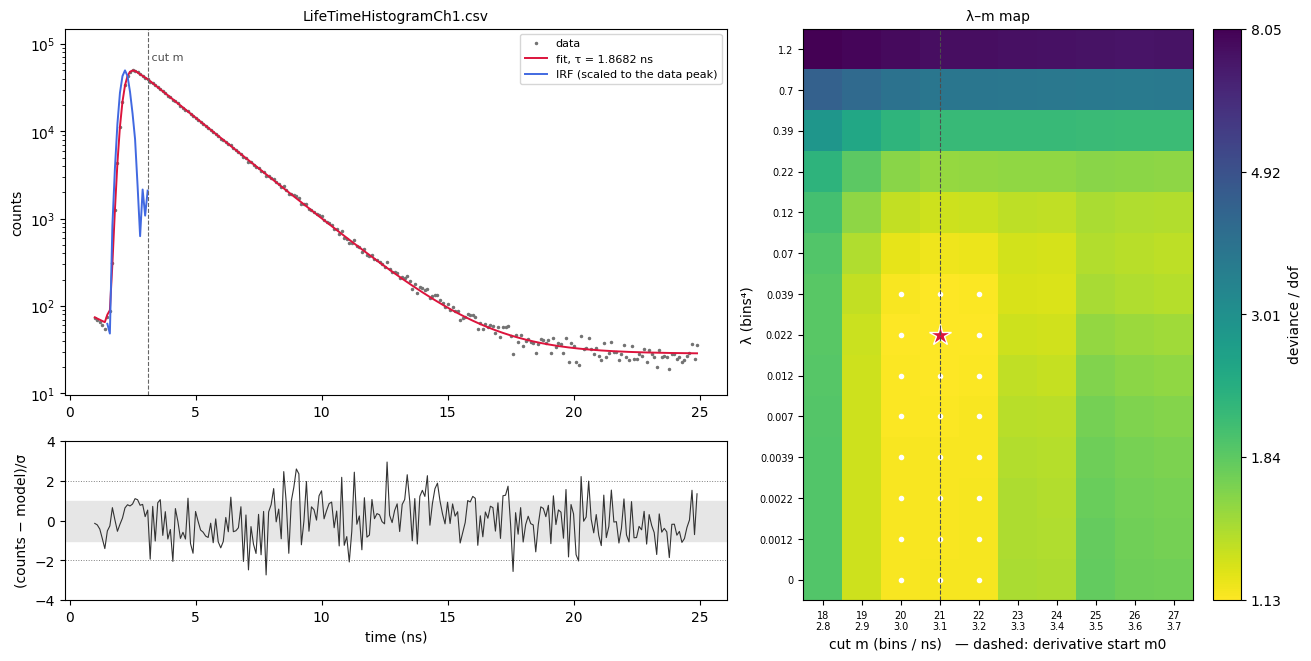

In [9]:
def analyse_decay(time_all_ns, counts_all, margin_ns=0.8):
    """
    The whole λ-m analysis of one decay (steps 1-5).

    Why:    one reusable call. It chains the functions above in pipeline order.
    Input:  time_all_ns, counts_all - the full histogram (ns, photons per bin)
            margin_ns               - how far before the rise the window starts (ns)
    Output: dictionary with
              time_ns, counts      window time axis (ns) and raw counts
              first_bin            index of the window's first bin in the file
              background_median    far-tail background (counts/bin)
              rise_bins            10-90 % rise time (bins)
              m0                   starting cut from the derivative (bins)
              lambda_grid, m_grid  scanned values
              deviance_per_dof     scan score map [i_lambda, i_m]
              tau_map              τ of every pair (ns)
              near_best            pairs within 5 % of the best deviance/dof
              best_lambda, best_m  chosen pair
              irf                  unit-area IRF on bins 0..best_m of the window
              tau_ns, tau_statistical_ns, tau_systematic_ns
              amplitude, background_fit   linear fit parameters
              model                expected counts per bin of the final fit
              residuals            (counts - model)/sqrt(model): units of the Poisson σ
              deviance, degrees_of_freedom
    """
    background_median = estimate_background(counts_all)
    time_ns, counts, first_bin = crop_before_rise(time_all_ns, counts_all, background_median, margin_ns)
    y = counts - background_median
    rise_bins = measure_rise_time(counts, background_median)
    m0 = find_initial_cut(y, rise_bins)
    lambda_grid = make_lambda_grid(rise_bins)
    m_grid = make_m_grid(m0, counts.size)
    deviance_per_dof, tau_map = lambda_m_scan(time_ns, counts, y, lambda_grid, m_grid)
    best_lambda, best_m, tau_ns, tau_systematic_ns, near_best = select_best_pair(
        deviance_per_dof, tau_map, lambda_grid, m_grid)
    irf = normalise_irf(deconvolve_irf(whittaker_smooth(y, best_lambda), best_m))
    tau_statistical_ns = lifetime_statistical_error(tau_ns, time_ns, counts, irf)
    amplitude, background_fit, model = fit_amplitude_and_background(
        decay_shape(time_ns, irf, tau_ns), counts)
    return dict(
        time_ns=time_ns, counts=counts, first_bin=first_bin,
        background_median=background_median, rise_bins=rise_bins, m0=m0,
        lambda_grid=lambda_grid, m_grid=m_grid, deviance_per_dof=deviance_per_dof,
        tau_map=tau_map, near_best=near_best, best_lambda=best_lambda, best_m=best_m,
        irf=irf, tau_ns=tau_ns, tau_statistical_ns=tau_statistical_ns,
        tau_systematic_ns=tau_systematic_ns, amplitude=amplitude, background_fit=background_fit,
        model=model, residuals=(counts - model) / np.sqrt(np.maximum(model, 1e-12)),
        deviance=poisson_deviance(counts, model), degrees_of_freedom=counts.size - 3)


def print_summary(results):
    """
    Print the main numbers of an analysis.

    Why:    the lifetime with both errors, the chosen pair in physical terms, and the fit
            quality, in one place.
    Input:  results - dictionary returned by analyse_decay
    """
    r = results
    t = r["time_ns"]
    bin_width_ns = t[1] - t[0]
    lam = r["best_lambda"]
    cutoff = cutoff_for_lambda(lam)
    if lam == 0:
        smoothing = "no smoothing"
    elif cutoff is None:
        smoothing = f"no cutoff below Nyquist; gain at Nyquist {1 / (1 + 16 * lam):.2f}"
    else:
        smoothing = f"cutoff period {cutoff:.1f} bins = {cutoff * bin_width_ns:.3f} ns"
    print(f"Lifetime      τ = {r['tau_ns']:.4f} ± {r['tau_statistical_ns']:.4f} (statistical)"
          f" ± {r['tau_systematic_ns']:.4f} (systematic) ns")
    print(f"Smoothing     λ = {lam:.4g} bins⁴ ({smoothing})")
    print(f"Cut           m = {r['best_m']} bins into the window -> t = {t[r['best_m']]:.2f} ns;"
          f" IRF length {r['best_m'] + 1} bins = {(r['best_m'] + 1) * bin_width_ns:.2f} ns"
          f" (derivative start m0 = {r['m0']})")
    print(f"Fit quality   deviance/dof = {r['deviance'] / r['degrees_of_freedom']:.3f}"
          f" ({r['deviance']:.1f} / {r['degrees_of_freedom']})")
    print(f"Background    {r['background_fit']:.1f} counts/bin (fitted), "
          f"{r['background_median']:.1f} (far-tail median)")
    print(f"Window        {t[0]:.2f} – {t[-1]:.2f} ns ({t.size} bins from bin {r['first_bin']});"
          f" rise time {r['rise_bins']:.2f} bins")


def plot_results(results, title=""):
    """
    The result figure: (1) data, fit and IRF on a log scale; (2) residuals in units of σ;
    (3) the λ-m map of deviance/dof with the chosen pair marked.

    Why:    (1) shows the fit and where the IRF sits relative to the rise; (2) shows whether
            the misfit is noise (a band about ±1 wide) or structure; (3) shows whether the
            chosen pair is a well-defined minimum, and which pairs set the systematic error.
    Input:  results - dictionary returned by analyse_decay; title - figure title
    Output: the Matplotlib figure
    """
    r = results
    t, counts, irf = r["time_ns"], r["counts"], r["irf"]
    figure = plt.figure(figsize=(13, 6.5), constrained_layout=True)
    layout = figure.add_gridspec(2, 2, width_ratios=(1.7, 1), height_ratios=(3, 1.3))
    ax_fit = figure.add_subplot(layout[0, 0])
    ax_residuals = figure.add_subplot(layout[1, 0], sharex=ax_fit)
    ax_map = figure.add_subplot(layout[:, 1])

    # (1) data, fitted model, IRF scaled to the data peak (zeros hidden on the log axis)
    irf_scaled = irf * counts.max() / irf.max()
    ax_fit.semilogy(t, counts, ".", ms=3, color="0.45", label="data")
    ax_fit.semilogy(t, r["model"], color="crimson", lw=1.4, label=f"fit, τ = {r['tau_ns']:.4f} ns")
    ax_fit.semilogy(t[: irf.size], np.where(irf_scaled > 0, irf_scaled, np.nan),
                    color="royalblue", lw=1.4, label="IRF (scaled to the data peak)")
    ax_fit.axvline(t[r["best_m"]], ls="--", lw=0.8, color="0.4")
    ax_fit.text(t[r["best_m"]], counts.max() * 1.3, " cut m", fontsize=8, color="0.3")
    ax_fit.set_ylim(0.5 * counts[counts > 0].min(), 3 * counts.max())
    ax_fit.set_ylabel("counts")
    ax_fit.legend(fontsize=8)
    ax_fit.set_title(title, fontsize=10)

    # (2) residuals in units of the Poisson σ = sqrt(model); grey band = ±1 σ
    ax_residuals.axhspan(-1, 1, color="0.9")
    for level in (-2, 2):
        ax_residuals.axhline(level, ls=":", lw=0.7, color="0.5")
    ax_residuals.plot(t, r["residuals"], lw=0.8, color="0.2")
    limit = max(4.0, 1.1 * np.abs(r["residuals"]).max())
    ax_residuals.set_ylim(-limit, limit)
    ax_residuals.set_xlabel("time (ns)")
    ax_residuals.set_ylabel("(counts − model)/σ")

    # (3) λ-m map: rows = λ, columns = m; white dots = within 5 %, star = chosen pair
    score = np.ma.masked_invalid(r["deviance_per_dof"])
    n_lambda, n_m = score.shape
    image = ax_map.pcolormesh(np.arange(n_m + 1) - 0.5, np.arange(n_lambda + 1) - 0.5, score,
                              cmap="viridis_r", norm=LogNorm())
    rows, columns = np.nonzero(r["near_best"])
    ax_map.plot(columns, rows, "o", ms=3, color="white")
    i_best = int(np.flatnonzero(r["lambda_grid"] == r["best_lambda"])[0])
    j_best = int(np.flatnonzero(r["m_grid"] == r["best_m"])[0])
    ax_map.plot(j_best, i_best, "*", ms=16, color="crimson", markeredgecolor="white")
    ax_map.axvline(int(np.flatnonzero(r["m_grid"] == r["m0"])[0]), ls="--", lw=0.8, color="0.3")
    ax_map.set_xticks(np.arange(n_m))
    ax_map.set_xticklabels([f"{m}\n{t[m]:.1f}" for m in r["m_grid"]], fontsize=7)
    ax_map.set_yticks(np.arange(n_lambda))
    ax_map.set_yticklabels(["0"] + [f"{lam:.2g}" for lam in r["lambda_grid"][1:]], fontsize=7)
    ax_map.set_xlabel("cut m (bins / ns)   — dashed: derivative start m0")
    ax_map.set_ylabel("λ (bins⁴)")
    colour_bar = figure.colorbar(image, ax=ax_map, label="deviance / dof")
    tick_values = np.geomspace(score.min(), score.max(), 5)     # plain numbers, not 10^0 notation
    colour_bar.set_ticks(tick_values)
    colour_bar.set_ticklabels([f"{value:.3g}" for value in tick_values])
    colour_bar.ax.minorticks_off()
    ax_map.set_title("λ–m map", fontsize=10)
    return figure


# --- run the whole analysis on the data in one call ---
results = analyse_decay(time_all_ns, counts_all)
assert np.isclose(results["tau_ns"], tau_best) and results["best_m"] == best_m   # same as steps 1-5
print_summary(results)
plot_results(results, title=DATA_FILE)
plt.show()

## IRF convergence across the λ–m grid

The scan keeps only a score per pair. To see how the IRF itself changes across the grid, each pair's IRF is re-extracted exactly as in the scan. Four views: (a) the chosen cut, every λ — what smoothing does; (b) the chosen λ, every cut — what the cut does; (c) how far each pair's IRF is from the chosen one, with the near-best pairs marked; (d) the band spanned by the near-best IRFs — which parts of the IRF the choice of (λ, *m*) leaves uncertain.

near-best pairs: 24; their IRFs differ from the chosen one by 0.0–2.7 %
IRF peak height over the near-best pairs: 2.2 % range; peak bin always at t = 2.20 ns: True


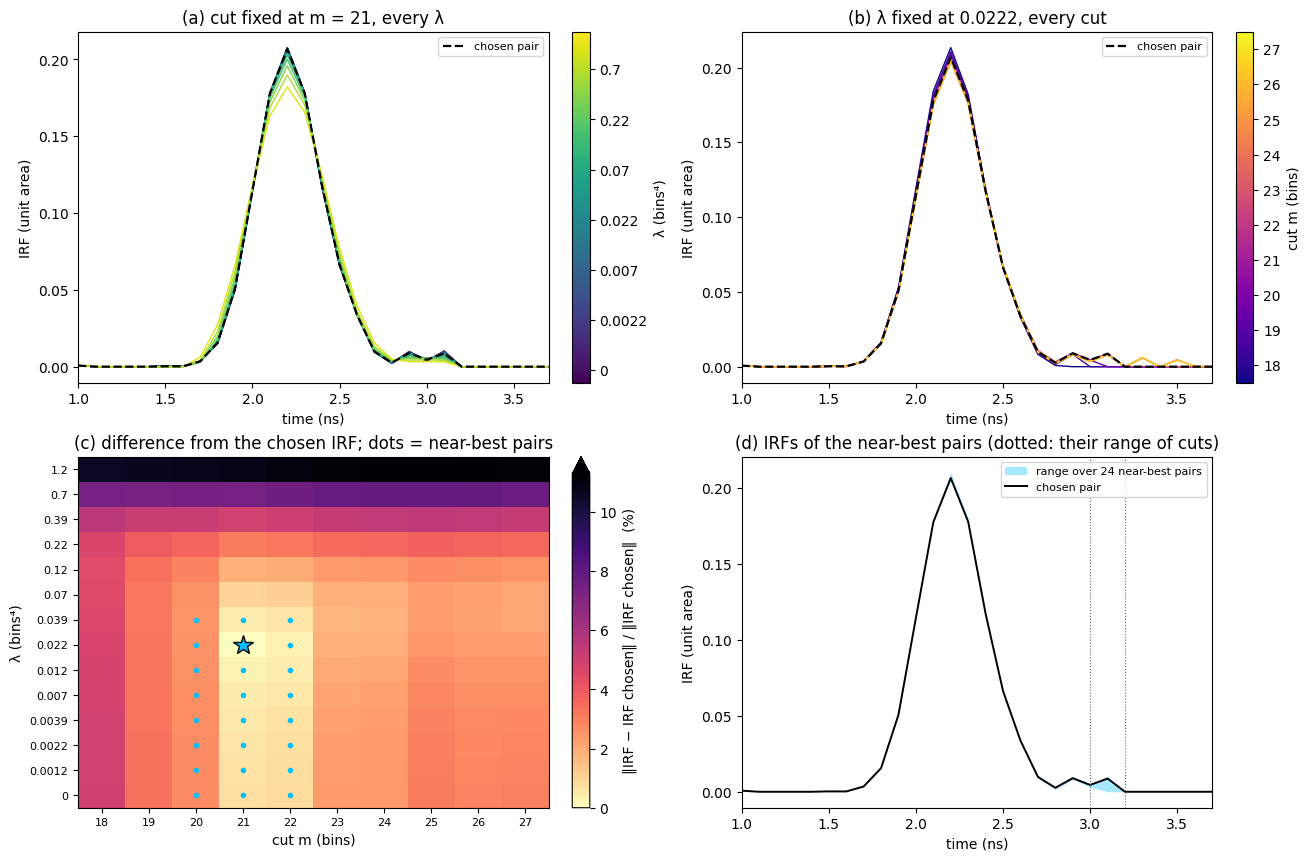

In [10]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def irf_family(results):
    """
    The IRF of every (λ, m) pair of the scan, on a common time axis.

    Why:    the scan stores only scores. To see how the IRF itself changes across the grid -
            and whether pairs that fit almost equally well also agree on the IRF - every
            pair's IRF is re-extracted exactly as in the scan (one smoothing per λ, cheap).
    Input:  results - dictionary returned by analyse_decay
    Output: irfs[i_lambda, i_m, k] - unit-area IRF of each pair, zero after its own last
                                     sample m (an IRF is zero beyond its support)
            distance[i_lambda, i_m] - relative difference from the chosen IRF,
                                     ||IRF_pair - IRF_chosen|| / ||IRF_chosen||
    Used by: plot_irf_convergence.
    """
    y = results["counts"] - results["background_median"]
    lambda_grid, m_grid = results["lambda_grid"], results["m_grid"]
    n_samples = int(m_grid.max()) + 1                     # longest IRF in the grid
    irfs = np.zeros((lambda_grid.size, m_grid.size, n_samples))
    for i, lam in enumerate(lambda_grid):
        y_smoothed = whittaker_smooth(y, lam)
        for j, m in enumerate(m_grid):
            irf = normalise_irf(deconvolve_irf(y_smoothed, m))
            if irf is not None:
                irfs[i, j, : irf.size] = irf
    chosen = np.zeros(n_samples)
    chosen[: results["irf"].size] = results["irf"]
    distance = np.linalg.norm(irfs - chosen, axis=2) / np.linalg.norm(chosen)
    return irfs, distance


def plot_irf_convergence(results):
    """
    Four views of how the IRF changes across the λ-m grid.

    Why:    the deviance map says which pairs FIT well; this shows whether they also AGREE
            on the IRF, and which parts of the IRF depend on the choice of (λ, m).
            (a) chosen m, every λ: small λ leaves the IRF ragged, large λ broadens it.
            (b) chosen λ, every m: an early cut truncates the IRF, a late one adds samples.
            (c) difference from the chosen IRF for every pair; dots = near-best pairs.
            (d) envelope (min-max) of the near-best IRFs around the chosen one.
    Input:  results - dictionary returned by analyse_decay
    Output: the Matplotlib figure; also prints how much the near-best IRFs differ.
    """
    r = results
    irfs, distance = irf_family(r)
    lambda_grid, m_grid, near_best = r["lambda_grid"], r["m_grid"], r["near_best"]
    i_best = int(np.flatnonzero(lambda_grid == r["best_lambda"])[0])
    j_best = int(np.flatnonzero(m_grid == r["best_m"])[0])
    time_irf = r["time_ns"][: irfs.shape[2]]
    chosen = irfs[i_best, j_best]
    lambda_labels = ["0"] + [f"{lam:.2g}" for lam in lambda_grid[1:]]

    figure, axes = plt.subplots(2, 2, figsize=(13, 8.5), constrained_layout=True)
    (ax_lambda, ax_m), (ax_map, ax_band) = axes

    # (a) the chosen cut, every λ
    lambda_colours = plt.cm.viridis(np.linspace(0, 0.95, lambda_grid.size))
    for i in range(lambda_grid.size):
        ax_lambda.plot(time_irf, irfs[i, j_best], color=lambda_colours[i], lw=1.0)
    ax_lambda.plot(time_irf, chosen, "k--", lw=1.6, label="chosen pair")
    bar = figure.colorbar(ScalarMappable(Normalize(-0.5, lambda_grid.size - 0.5), "viridis"), ax=ax_lambda)
    bar.set_ticks(np.arange(0, lambda_grid.size, 2)); bar.set_ticklabels(lambda_labels[::2]); bar.set_label("λ (bins⁴)")
    ax_lambda.set(title=f"(a) cut fixed at m = {r['best_m']}, every λ", xlabel="time (ns)", ylabel="IRF (unit area)")
    ax_lambda.legend(fontsize=8)

    # (b) the chosen λ, every cut
    m_colours = plt.cm.plasma(np.linspace(0, 0.9, m_grid.size))
    for j in range(m_grid.size):
        ax_m.plot(time_irf, irfs[i_best, j], color=m_colours[j], lw=1.0)
    ax_m.plot(time_irf, chosen, "k--", lw=1.6, label="chosen pair")
    bar = figure.colorbar(ScalarMappable(Normalize(-0.5, m_grid.size - 0.5), "plasma"), ax=ax_m)
    bar.set_ticks(np.arange(m_grid.size)); bar.set_ticklabels([str(m) for m in m_grid]); bar.set_label("cut m (bins)")
    ax_m.set(title=f"(b) λ fixed at {r['best_lambda']:.3g}, every cut", xlabel="time (ns)", ylabel="IRF (unit area)")
    ax_m.legend(fontsize=8)

    # (c) difference from the chosen IRF, in %
    n_lambda, n_m = distance.shape
    image = ax_map.pcolormesh(np.arange(n_m + 1) - 0.5, np.arange(n_lambda + 1) - 0.5, 100 * distance,
                              cmap="magma_r", vmin=0, vmax=min(100 * distance.max(), 40))
    rows, columns = np.nonzero(near_best)
    ax_map.plot(columns, rows, "o", ms=3, color="deepskyblue")
    ax_map.plot(j_best, i_best, "*", ms=15, color="deepskyblue", markeredgecolor="k")
    ax_map.set_xticks(np.arange(n_m)); ax_map.set_xticklabels([str(m) for m in m_grid], fontsize=8)
    ax_map.set_yticks(np.arange(n_lambda)); ax_map.set_yticklabels(lambda_labels, fontsize=8)
    ax_map.set(title="(c) difference from the chosen IRF; dots = near-best pairs", xlabel="cut m (bins)", ylabel="λ (bins⁴)")
    figure.colorbar(image, ax=ax_map, label="‖IRF − IRF chosen‖ / ‖IRF chosen‖  (%)", extend="max")

    # (d) envelope of the near-best IRFs
    near_irfs = irfs[near_best]
    ax_band.fill_between(time_irf, near_irfs.min(axis=0), near_irfs.max(axis=0), color="deepskyblue",
                         alpha=0.35, lw=0, label=f"range over {near_irfs.shape[0]} near-best pairs")
    ax_band.plot(time_irf, chosen, "k", lw=1.4, label="chosen pair")
    for m in (m_grid[np.any(near_best, axis=0)].min(), m_grid[np.any(near_best, axis=0)].max()):
        ax_band.axvline(r["time_ns"][m], ls=":", lw=0.8, color="0.4")
    ax_band.set(title="(d) IRFs of the near-best pairs (dotted: their range of cuts)", xlabel="time (ns)", ylabel="IRF (unit area)")
    ax_band.legend(fontsize=8)

    for ax in (ax_lambda, ax_m, ax_band):
        ax.set_xlim(time_irf[0], time_irf[-1])

    # numbers behind the picture
    peak_bin = int(np.argmax(chosen))
    peaks = near_irfs.max(axis=1)
    print(f"near-best pairs: {near_irfs.shape[0]}; their IRFs differ from the chosen one by "
          f"{100 * distance[near_best].min():.1f}–{100 * distance[near_best].max():.1f} %")
    print(f"IRF peak height over the near-best pairs: {100 * (peaks.max() - peaks.min()) / chosen.max():.1f} % range;"
          f" peak bin always at t = {r['time_ns'][peak_bin]:.2f} ns: "
          f"{bool(np.all(np.argmax(near_irfs, axis=1) == peak_bin))}")
    return figure


# --- run on the data ---
plot_irf_convergence(results)
plt.show()

## Verification on a synthetic decay with a known IRF and τ

Real data have no known answer, so we build a decay whose IRF and lifetime we chose, save it in the same file format, and run exactly the same analysis. The test uses a *structured* IRF — a main peak plus a satellite — so it checks the recovered **shape**, not just a width, and a different lifetime from the measured one.

Lifetime      τ = 1.2024 ± 0.0013 (statistical) ± 0.0041 (systematic) ns
Smoothing     λ = 0.01026 bins⁴ (no cutoff below Nyquist; gain at Nyquist 0.86)
Cut           m = 21 bins into the window -> t = 3.00 ns; IRF length 22 bins = 2.20 ns (derivative start m0 = 21)
Fit quality   deviance/dof = 0.941 (224.1 / 238)
Background    25.3 counts/bin (fitted), 26.0 (far-tail median)
Window        0.90 – 24.90 ns (241 bins from bin 9); rise time 4.03 bins

true τ = 1.2000 ns; found − true = +2.4 ps = +0.57 x the combined error
IRF shape: relative error 0.027; true peak at 2.00 ns, found at 2.00 ns


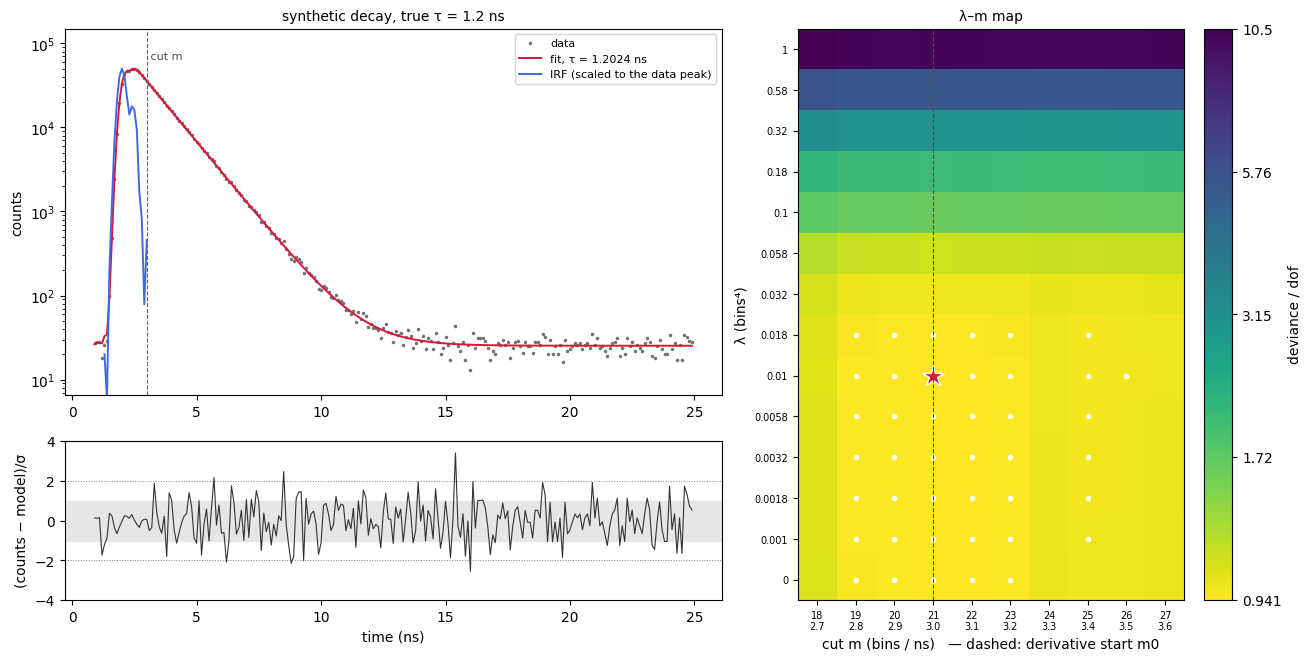

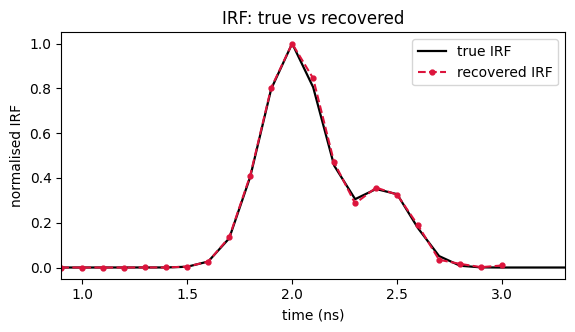

In [11]:
def gaussian(time_ns, centre_ns, fwhm_ns):
    """Gaussian peak with a given centre and full width at half maximum (ns), peak value 1."""
    sigma_ns = fwhm_ns / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    return np.exp(-0.5 * ((time_ns - centre_ns) / sigma_ns) ** 2)


def make_synthetic_decay(tau_ns=1.2, peak_counts=5e4, background=25.0, seed=0,
                         bin_width_ns=0.1, n_bins=250):
    """
    Synthetic TCSPC histogram with a known IRF and lifetime.

    Why:    the only way to show the analysis recovers the truth is to know the truth.
            Same binning as the measured file. The IRF has a main peak (FWHM 0.35 ns at
            2.0 ns) and a satellite (FWHM 0.30 ns at 2.45 ns, 35 % of the main height).
            The expected counts follow the same discrete model the fit uses,
            A·(IRF ⊛ exp(-t/τ)) + b, and each bin then gets Poisson noise.
    Input:  tau_ns (ns), peak_counts (photons in the highest bin above background),
            background (photons per bin), seed (random generator seed), binning
    Output: time_ns, counts, irf_true (unit area, on the full time axis)
    """
    time_ns = np.arange(n_bins) * bin_width_ns
    irf_true = gaussian(time_ns, 2.0, 0.35) + 0.35 * gaussian(time_ns, 2.45, 0.30)
    irf_true /= irf_true.sum()
    noise_free_decay = np.convolve(irf_true, np.exp(-time_ns / tau_ns))[:n_bins]
    expected_counts = peak_counts * noise_free_decay / noise_free_decay.max() + background
    counts = np.random.default_rng(seed).poisson(expected_counts).astype(float)
    return time_ns, counts, irf_true


def irf_relative_error(results, irf_true_full):
    """
    Relative L2 difference between the recovered IRF and the true one, on the window.

    Why:    a single number for how well the IRF shape is recovered (0 = perfect).
    Input:  results (from analyse_decay); irf_true_full (true IRF on the file's time axis)
    Output: ||IRF_found - IRF_true|| / ||IRF_true||
    """
    true_in_window = irf_true_full[results["first_bin"]:]
    true_in_window = true_in_window / true_in_window.sum()
    found = np.zeros_like(true_in_window)
    found[: results["irf"].size] = results["irf"]
    return np.linalg.norm(found - true_in_window) / np.linalg.norm(true_in_window)


# --- one synthetic decay, written to and read back from a CSV like the measured one ---
TAU_TRUE_NS = 1.2
synthetic_time, synthetic_counts, irf_true = make_synthetic_decay(tau_ns=TAU_TRUE_NS, seed=0)
np.savetxt("synthetic_decay.csv", np.column_stack([synthetic_time, synthetic_counts]),
           delimiter=",", fmt="%.3f", header="Time(ns), Counts")
synthetic = analyse_decay(*load_decay("synthetic_decay.csv"))
print_summary(synthetic)

total_error = np.hypot(synthetic["tau_statistical_ns"], synthetic["tau_systematic_ns"])
print(f"\ntrue τ = {TAU_TRUE_NS:.4f} ns; found − true = {1000 * (synthetic['tau_ns'] - TAU_TRUE_NS):+.1f} ps"
      f" = {(synthetic['tau_ns'] - TAU_TRUE_NS) / total_error:+.2f} x the combined error")
print(f"IRF shape: relative error {irf_relative_error(synthetic, irf_true):.3f};"
      f" true peak at {synthetic_time[np.argmax(irf_true)]:.2f} ns,"
      f" found at {synthetic['time_ns'][np.argmax(synthetic['irf'])]:.2f} ns")

plot_results(synthetic, title=f"synthetic decay, true τ = {TAU_TRUE_NS} ns")
plt.show()

window = synthetic["time_ns"]
plt.figure(figsize=(6.5, 3.2))
plt.plot(window, irf_true[synthetic["first_bin"]:] / irf_true[synthetic["first_bin"]:].max(),
         "k", lw=1.6, label="true IRF")
plt.plot(window[: synthetic["irf"].size], synthetic["irf"] / synthetic["irf"].max(),
         "o--", ms=3.5, color="crimson", label="recovered IRF")
plt.xlim(window[0], window[synthetic["best_m"]] + 0.3)
plt.xlabel("time (ns)"); plt.ylabel("normalised IRF"); plt.legend()
plt.title("IRF: true vs recovered"); plt.show()

One synthetic decay can be lucky. Repeating it with fresh noise tests two things: that τ is **unbiased**, and that the reported errors are **honest** — about 68 % of results should fall within 1 combined error of the truth, and about 95 % within 2.

In [12]:
N_REALISATIONS = 20          # independent noise realisations (each runs the full analysis)

found_taus, combined_errors, irf_errors = [], [], []
start = time.perf_counter()
for seed in range(1, N_REALISATIONS + 1):
    time_s, counts_s, irf_true_s = make_synthetic_decay(tau_ns=TAU_TRUE_NS, seed=seed)
    r = analyse_decay(time_s, counts_s)
    found_taus.append(r["tau_ns"])
    combined_errors.append(np.hypot(r["tau_statistical_ns"], r["tau_systematic_ns"]))
    irf_errors.append(irf_relative_error(r, irf_true_s))
found_taus, combined_errors = np.array(found_taus), np.array(combined_errors)
deviations = found_taus - TAU_TRUE_NS

print(f"{N_REALISATIONS} realisations in {time.perf_counter() - start:.0f} s")
print(f"bias of τ:              {1000 * deviations.mean():+.2f} ± {1000 * deviations.std(ddof=1) / np.sqrt(N_REALISATIONS):.2f} ps")
print(f"actual scatter of τ:    {1000 * deviations.std(ddof=1):.2f} ps")
print(f"mean combined error:    {1000 * combined_errors.mean():.2f} ps")
print(f"within 1 combined error: {np.mean(np.abs(deviations) < combined_errors):.0%}   (expected ≈ 68 %)")
print(f"within 2 combined errors: {np.mean(np.abs(deviations) < 2 * combined_errors):.0%}   (expected ≈ 95 %)")
print(f"IRF relative error:     {np.mean(irf_errors):.3f} on average")

20 realisations in 161 s
bias of τ:              -1.44 ± 0.64 ps
actual scatter of τ:    2.88 ps
mean combined error:    3.27 ps
within 1 combined error: 80%   (expected ≈ 68 %)
within 2 combined errors: 85%   (expected ≈ 95 %)
IRF relative error:     0.030 on average


**What the verification shows** (fixed seeds, so these numbers reproduce):

- **τ is recovered without meaningful bias**: about −1.4 ± 0.6 ps on 1.2 ns. The IRF shape is recovered to about 3 %, satellite peak included.
- **The statistical error alone is too small.** It is about 1.3 ps, but the real scatter of τ is about 2.9 ps: the Δ-deviance error treats the IRF as exact, while the IRF is re-extracted from noisy data every time.
- **The systematic error is right on average but unstable.** It ranges from about 0.2 to 5.8 ps between realisations, because it depends on how many pairs happen to fall within 5 % of the best. When it comes out small, the combined error is too small: here 80 % of results fall within 1 combined error (68 % expected) but only 85 % within 2 (95 % expected).

So treat the combined error as an estimate of the right size, not a calibrated one.